# Analisis Jangkauan Pos Pemadam Kebakaran — Surabaya Timur
Team 4 · Computer Graphics 2026/2027

Alur: validasi data → proyeksi EPSG:32749 → buffer pos → spatial join dengan kecamatan → profil 24 jam → waktu tempuh rute TomTom (jam lengang vs jam puncak hasil pengukuran).

**Data yang harus ada di `data/`:**
- `kejadian_sijalinmaja_2026.csv`: kejadian kebakaran 2026 di 11 kecamatan studi dari SIJALINMAJA Jatim (snapshot 30-10-2026)
- `pos_damkar.csv`: kolom `nama, jenis (rayon/pembantu), lon, lat` (koordinat **wajib diisi** & diverifikasi)
- `idn_admin_boundaries.gdb.zip` (atau hasil unzip `.gdb`) dari HDX: hanya dibutuhkan sekali, notebook menyimpan 11 kecamatan ke `kecamatan_surabaya.geojson`

API key TomTom (gratis, developer.tomtom.com): simpan di file `.tomtom_key`, set env `TOMTOM_API_KEY`, atau masukkan saat diminta oleh cell waktu tempuh.

**Kesesuaian dengan proposal.** Inti proposal: 2 layer (titik pos, batas kecamatan), 2 operasi (buffer, spatial join), fitur tambahan waktu tempuh rute berbasis lalu lintas minimal 2 skenario jam.
Bagian di luar proposal yang **sudah disetujui**: 6.1 profil 24 jam (dasar memilih jam ramai), bagian 7 (titik kejadian vs buffer), peta Folium, dan data SIJALINMAJA 2026. Isochrone sudah dihapus.

In [1]:
%pip install -q geopandas matplotlib requests folium

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, re
from datetime import date, datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests

DATA = Path("data")
OUT = Path("output"); OUT.mkdir(exist_ok=True)
KECAMATAN_PATH = DATA / "kecamatan_surabaya.geojson"   # hasil potongan, dibuat otomatis dari file HDX
HDX_GDB = [DATA / "idn_admin_boundaries.gdb", DATA / "idn_admin_boundaries.gdb.zip"]   # download dari HDX cod-ab-idn

STUDI = ["Gubeng", "Gunung Anyar", "Mulyorejo", "Rungkut", "Sukolilo", "Tambaksari",
         "Tenggilis Mejoyo", "Bulak", "Kenjeran", "Genteng", "Wonocolo"]
CRS_UTM = "EPSG:32749"
RADIUS_M = {"pembantu": 2500, "rayon": 3500}   # Permen PU 20/PRT/M/2009
TANGGAL_SAMPEL = date(2026, 10, 28)              # hari yang disimulasikan TomTom (Rabu = hari kerja); ganti tanggal untuk hari lain
# Jam skenario. None = dipilih otomatis dari profil 24 jam (bagian 6.1).
# Atur sendiri dengan daftar jam bulat 0-23, mis. [2, 5, 17] (tulis 5, bukan 05).
# Satu angka saja (mis. 6) = jam itu dibandingkan dengan jam lengang otomatis (sekitar 02.00).
# Boleh juga dengan nama: {"lengang": 2, "subuh": 5, "sore": 17}.
# Yang pertama = jam lengang pembanding; minimal 2 skenario (syarat proposal).
JAM_SKENARIO = 6
TAHUN = 2026                                     # data kebakaran: SIJALINMAJA, hanya tahun ini
TANGGAL_SNAPSHOT = date(2026, 10, 30)            # kejadian bertanggal setelah ini dianggap salah input
BATAS_TEMPUH_MENIT = 5                          # porsi perjalanan dari 15 menit waktu tanggap

def kunci(nama):
    # samakan penulisan nama kecamatan: 'Gunung Anyar' == 'Gununganyar'
    return re.sub(r"[^a-z]", "", str(nama).lower())

In [3]:
import folium, webbrowser
from html import escape
from branca.colormap import LinearColormap
from IPython.display import display

# Semua peta memakai Folium. Tiap peta juga disimpan sebagai HTML di output/.
# Kalau output peta di notebook kosong/"Make this Notebook Trusted": jalankan ulang cell-nya (output baru selalu tampil),
# atau set True agar setiap peta dibuka di browser.
BUKA_DI_BROWSER = False

wgs = lambda g: g.to_crs("EPSG:4326")
label = lambda n: n.replace("_", " ")
BOUNDS_SURABAYA_TIMUR = [
    [-7.3465, 112.7293],
    [-7.1957, 112.8468],
]

def peta_baru():
    m = folium.Map(
        location=[-7.28, 112.78],
        zoom_start=12,
        min_zoom=11,
        max_bounds=True,
        max_bounds_viscosity=1.0,
        tiles="OpenStreetMap",
    )
    m.fit_bounds(BOUNDS_SURABAYA_TIMUR)
    return m
def judul(m, teks):
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:fixed;top:8px;left:55px;z-index:9999;background:white;padding:4px 10px;border-radius:4px;'
        f'font:bold 13px sans-serif;box-shadow:0 0 4px gray">{escape(teks)}</div>'))

def legenda(m, teks, item):
    baris = "".join(f'<div><span style="background:{w};opacity:.7;display:inline-block;width:14px;height:14px;margin-right:6px"></span>{escape(k)}</div>'
                    for k, w in item.items())
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:fixed;bottom:25px;left:10px;z-index:9999;background:white;padding:8px 10px;border-radius:4px;'
        f'font:12px sans-serif;box-shadow:0 0 4px gray"><b>{escape(teks)}</b>{baris}</div>'))

def tandai_pos(m):
    for _, r in pos.iterrows():
        folium.Marker((r.geometry.y, r.geometry.x), tooltip=f"{r['nama']} ({r['jenis']})",
                      icon=folium.Icon(color="red", icon="fire-extinguisher", prefix="fa")).add_to(m)

def simpan(m, nama):
    path = OUT / f"{nama}.html"
    m.save(path)
    print("Peta tersimpan:", path)
    if BUKA_DI_BROWSER:
        webbrowser.open(path.resolve().as_uri())
    return m

## 1. Data kejadian kebakaran 2026 per kecamatan (SIJALINMAJA)

In [4]:
raw = pd.read_csv(DATA / "kejadian_sijalinmaja_2026.csv")
raw = raw[(raw["tanggal_kejadian"].str[:4] == str(TAHUN)) & raw["nama_kecamatan"].map(kunci).isin({kunci(k) for k in STUDI})]
masa_depan = raw["tanggal_kejadian"] > str(TANGGAL_SNAPSHOT)
print(f"{len(raw)} kejadian {TAHUN} di 11 kecamatan studi, {raw['tanggal_kejadian'].min()} s/d {raw['tanggal_kejadian'].max()}")
print(f"{masa_depan.sum()} kejadian bertanggal setelah {TANGGAL_SNAPSHOT} (salah input, tidak dihitung); perlu dikoreksi di sumbernya:")
display(raw.loc[masa_depan, ["id", "tanggal_kejadian", "nama_kecamatan", "lokasi_kejadian"]])
raw = raw[~masa_depan]

kejadian = (raw.assign(Kecamatan=raw["nama_kecamatan"].str.strip().str.title())
            .groupby("Kecamatan").size().rename("jumlah_kejadian").reset_index())
kejadian["key"] = kejadian["Kecamatan"].map(kunci)
print("Kejadian di wilayah studi:", kejadian["jumlah_kejadian"].sum())
kejadian.sort_values("jumlah_kejadian", ascending=False)

155 kejadian 2026 di 11 kecamatan studi, 2026-01-01 s/d 2026-12-19
8 kejadian bertanggal setelah 2026-10-30 (salah input, tidak dihitung); perlu dikoreksi di sumbernya:


,id,tanggal_kejadian,nama_kecamatan,lokasi_kejadian
147,43976,2026-11-05,SUKOLILO,Jl. Semolowaru Indah II Blok R No.23
148,43979,2026-11-17,TENGGILIS MEJOYO,Jl. Kendangsari Gang I
149,43982,2026-11-24,GUBENG,Jl. Bratang Binangun II No.30 (Toko Banguanan ...
150,43984,2026-12-01,SUKOLILO,Jl. Jangkungan Gg II No.9
151,43986,2026-12-05,RUNGKUT,Jl. Raya Kalirungkut No.72
152,43989,2026-12-17,WONOCOLO,Jl. Sidosermo II No.361 C
153,43991,2026-12-18,GENTENG,Jl. Kapasari (Depan Alfamart)
154,43993,2026-12-19,SUKOLILO,Perum. Klampis Paris Regency VI Blok G/18


Kejadian di wilayah studi: 147


,Kecamatan,jumlah_kejadian,key
7,Sukolilo,21,sukolilo
0,Bulak,19,bulak
3,Gunung Anyar,17,gununganyar
4,Kenjeran,16,kenjeran
2,Gubeng,15,gubeng
8,Tambaksari,13,tambaksari
6,Rungkut,11,rungkut
5,Mulyorejo,11,mulyorejo
1,Genteng,10,genteng
10,Wonocolo,10,wonocolo


## 2. Validasi layer

In [5]:
def validasi(gdf, id_col, nama):
    assert gdf.crs is not None, f"{nama}: CRS kosong"
    assert not gdf.geometry.is_empty.any() and gdf.geometry.notna().all(), f"{nama}: ada geometri kosong"
    if not gdf.geometry.is_valid.all():
        print(f"{nama}: geometri tidak valid diperbaiki dengan make_valid()")
        gdf = gdf.set_geometry(gdf.geometry.make_valid())
    assert gdf[id_col].is_unique, f"{nama}: {id_col} tidak unik"
    minx, miny, maxx, maxy = gdf.total_bounds   # EPSG:4326, urutan lon lalu lat
    assert 112.5 <= minx and maxx <= 113.0 and -7.5 <= miny and maxy <= -7.1, f"{nama}: koordinat di luar Surabaya / lon-lat tertukar"
    print(f"{nama}: {len(gdf)} fitur, CRS {gdf.crs.to_string()}, bounds {gdf.total_bounds.round(4)}")
    return gdf

### Layer 2 — Batas kecamatan (Polygon)

In [6]:
import pyogrio

if KECAMATAN_PATH.exists():
    kec_all = gpd.read_file(KECAMATAN_PATH)
else:
    gdb = next((p for p in HDX_GDB if p.exists()), None)
    assert gdb, f"Taruh file HDX di salah satu: {[str(p) for p in HDX_GDB]}"
    layer = next(n for n, _ in pyogrio.list_layers(gdb) if "adm3" in n.lower() or "admin3" in n.lower())
    # bbox Surabaya supaya tidak memuat seluruh Indonesia
    kec_all = gpd.read_file(gdb, layer=layer, bbox=(112.55, -7.40, 112.90, -7.15))
nama_col = next(c for c in ["adm3_name", "ADM3_EN", "ADM3_ID", "NAME_3", "shapeName", "WADMKC"] if c in kec_all.columns)
kota_col = next((c for c in ["adm2_name", "ADM2_EN", "ADM2_ID", "NAME_2", "WADMKK"] if c in kec_all.columns), None)
# nama seperti Genteng/Sukolilo juga ada di kabupaten lain, jadi filter Kota Surabaya dulu
if kota_col:
    kec_all = kec_all[kec_all[kota_col].str.contains("Surabaya", case=False, na=False)]

kec = kec_all.assign(key=kec_all[nama_col].map(kunci))
kec = kec[kec["key"].isin({kunci(k) for k in STUDI})].dissolve(by="key").reset_index()
hilang = {kunci(k) for k in STUDI} - set(kec["key"])
assert not hilang, f"Kecamatan tidak ditemukan di file batas: {hilang}"
if not KECAMATAN_PATH.exists():
    kec.to_file(KECAMATAN_PATH, driver="GeoJSON")   # simpan 11 kecamatan saja; file HDX boleh dihapus setelah ini

kec = kec.merge(kejadian[["key", "Kecamatan", "jumlah_kejadian"]], on="key", how="left")[["key", "Kecamatan", "jumlah_kejadian", "geometry"]]
kec = validasi(kec.to_crs("EPSG:4326"), "key", "Kecamatan")

Kecamatan: 11 fitur, CRS EPSG:4326, bounds [112.7293  -7.3465 112.8468  -7.1957]


### Layer 1 — Titik pos Damkar (Point)

In [7]:
pos_df = pd.read_csv(DATA / "pos_damkar.csv")
pos_df["jenis"] = pos_df["jenis"].str.strip().str.lower()
assert pos_df[["lon", "lat"]].notna().all().all(), "Isi dulu lon/lat semua pos di data/pos_damkar.csv"
assert pos_df["jenis"].isin(RADIUS_M).all(), f"jenis harus salah satu dari {list(RADIUS_M)}"
# urutan longitude lalu latitude; cek kasar masih di sekitar Surabaya agar tidak tertukar
assert pos_df["lon"].between(112.5, 113.0).all() and pos_df["lat"].between(-7.5, -7.1).all(), "Koordinat di luar Surabaya / lon-lat tertukar"
assert len(pos_df) >= 4, "Analisis memakai minimal 4 pos"
if not pos_df["nama"].str.contains("Menur", case=False).any():
    print("PERINGATAN: Pos Menur (disebut di proposal) belum ada di data/pos_damkar.csv; tambahkan lon/lat-nya.")

pos = gpd.GeoDataFrame(pos_df, geometry=gpd.points_from_xy(pos_df["lon"], pos_df["lat"]), crs="EPSG:4326")
pos = validasi(pos, "nama", "Pos Damkar")
pos

Pos Damkar: 7 fitur, CRS EPSG:4326, bounds [112.7364  -7.3367 112.8017  -7.2318]


,nama,jenis,lon,lat,geometry
0,Rayon/UPTD III (SIER),rayon,112.754070,-7.336707,POINT (112.75407 -7.33671)
1,Pos Kali Rungkut,pembantu,112.769998,-7.322148,POINT (112.77 -7.32215)
2,Pos Sukolilo (Keputih),pembantu,112.801729,-7.295276,POINT (112.80173 -7.29528)
3,Pos Bulak,pembantu,112.785459,-7.231831,POINT (112.78546 -7.23183)
4,UPTD II Tambak Rejo,rayon,112.759729,-7.243086,POINT (112.75973 -7.24309)
5,Mako Pasar Turi,rayon,112.736357,-7.244985,POINT (112.73636 -7.24498)
6,Pos Menur,pembantu,112.762941,-7.278230,POINT (112.76294 -7.27823)


## 3. Proyeksi ke UTM 49S (meter)

In [8]:
kec_m = kec.to_crs(CRS_UTM)
pos_m = pos.to_crs(CRS_UTM)
kec_m["luas_km2"] = (kec_m.area / 1e6).round(2)
kec_m[["Kecamatan", "jumlah_kejadian", "luas_km2"]]

,Kecamatan,jumlah_kejadian,luas_km2
0,Bulak,19,6.09
1,Genteng,10,4.12
2,Gubeng,15,7.90
3,Gunung Anyar,17,10.27
4,Kenjeran,16,8.64
5,Mulyorejo,11,17.73
6,Rungkut,11,22.93
7,Sukolilo,21,30.24
8,Tambaksari,13,8.88
9,Tenggilis Mejoyo,4,5.78


## 4. Operasi 1 — Buffer zona jangkauan

In [9]:
pos_m["radius_m"] = pos_m["jenis"].map(RADIUS_M)
buffer_m = pos_m.copy()
buffer_m["geometry"] = pos_m.buffer(pos_m["radius_m"])
buffer_m[["nama", "jenis", "radius_m"]]

,nama,jenis,radius_m
0,Rayon/UPTD III (SIER),rayon,3500
1,Pos Kali Rungkut,pembantu,2500
2,Pos Sukolilo (Keputih),pembantu,2500
3,Pos Bulak,pembantu,2500
4,UPTD II Tambak Rejo,rayon,3500
5,Mako Pasar Turi,rayon,3500
6,Pos Menur,pembantu,2500


## 5. Operasi 2 — Spatial join & status jangkauan

In [10]:
def status_jangkauan(kec_m, buffer_m):
    hit = gpd.sjoin(kec_m[["key", "geometry"]], buffer_m[["nama", "geometry"]], predicate="intersects")
    # satu kecamatan bisa cocok dengan beberapa buffer -> dihitung per kecamatan unik
    pos_per_kec = hit.groupby("key")["nama"].apply(lambda s: ", ".join(sorted(s)))
    centroid_masuk = kec_m.centroid.within(buffer_m.union_all())
    status = pd.Series("belum terjangkau", index=kec_m.index)
    status[kec_m["key"].isin(pos_per_kec.index)] = "terjangkau sebagian"
    status[centroid_masuk] = "terjangkau"
    return status, kec_m["key"].map(pos_per_kec).fillna("-")

kec_m["status"], kec_m["pos_beririsan"] = status_jangkauan(kec_m, buffer_m)
tabel_jarak = kec_m[["Kecamatan", "jumlah_kejadian", "status", "pos_beririsan"]].sort_values("jumlah_kejadian", ascending=False)
tabel_jarak

,Kecamatan,jumlah_kejadian,status,pos_beririsan
7,Sukolilo,21,terjangkau,"Pos Kali Rungkut, Pos Menur, Pos Sukolilo (Kep..."
0,Bulak,19,terjangkau,"Pos Bulak, UPTD II Tambak Rejo"
3,Gunung Anyar,17,terjangkau sebagian,"Pos Kali Rungkut, Rayon/UPTD III (SIER)"
4,Kenjeran,16,terjangkau,"Mako Pasar Turi, Pos Bulak, UPTD II Tambak Rejo"
2,Gubeng,15,terjangkau,"Mako Pasar Turi, Pos Kali Rungkut, Pos Menur, ..."
8,Tambaksari,13,terjangkau,"Mako Pasar Turi, Pos Bulak, Pos Menur, UPTD II..."
6,Rungkut,11,terjangkau sebagian,"Pos Kali Rungkut, Pos Sukolilo (Keputih), Rayo..."
5,Mulyorejo,11,terjangkau sebagian,"Pos Bulak, Pos Menur, Pos Sukolilo (Keputih), ..."
1,Genteng,10,terjangkau,"Mako Pasar Turi, Pos Menur, UPTD II Tambak Rejo"
10,Wonocolo,10,terjangkau,"Pos Kali Rungkut, Rayon/UPTD III (SIER)"


In [11]:
warna = {"terjangkau": "#4caf50", "terjangkau sebagian": "#ffc107", "belum terjangkau": "#e53935"}
m = peta_baru()
folium.GeoJson(wgs(kec_m[["Kecamatan", "jumlah_kejadian", "status", "pos_beririsan", "geometry"]]),
               style_function=lambda f: {"fillColor": warna[f["properties"]["status"]], "fillOpacity": 0.55, "color": "black", "weight": 1},
               tooltip=folium.GeoJsonTooltip(fields=["Kecamatan", "jumlah_kejadian", "status", "pos_beririsan"],
                                             aliases=["Kecamatan", f"Kejadian {TAHUN}", "Status", "Pos beririsan"])).add_to(m)
folium.GeoJson(wgs(buffer_m[["nama", "radius_m", "geometry"]]),   # garis saja (tanpa isi) supaya tooltip kecamatan tetap bisa dibaca
               style_function=lambda f: {"color": "navy", "weight": 1.5, "dashArray": "6,6", "fill": False},
               tooltip=folium.GeoJsonTooltip(fields=["nama", "radius_m"], aliases=["Pos", "Radius (m)"])).add_to(m)
tandai_pos(m)
judul(m, f"Jangkauan buffer pos Damkar vs kejadian kebakaran {TAHUN}")
legenda(m, "Status jangkauan", warna)
simpan(m, "peta_jangkauan_buffer")

Peta tersimpan: output\peta_jangkauan_buffer.html


## 6. Fitur tambahan — Waktu tempuh berdasarkan jam (TomTom)
Semua perhitungan memakai jaringan jalan dan lalu lintas historis TomTom pada `TANGGAL_SAMPEL` (hari kerja), bukan garis lurus.
1. **Profil 24 jam** *(di luar proposal, disetujui)*: jam lengang dan jam ramai dipilih dari data, bukan ditebak.
2. **Waktu tempuh rute**: dari setiap pos ke centroid setiap kecamatan, diambil pos tercepat, dibandingkan dengan batas 5 menit.

Semua respons disimpan di `output/tomtom_cache.json`; run ulang hanya mengirim request yang belum ada di cache.

In [12]:
import time
from getpass import getpass

WIB = ZoneInfo("Asia/Jakarta")
CACHE = OUT / "tomtom_cache.json"
cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}
sesi = requests.Session()   # pakai ulang koneksi TLS, jauh lebih cepat dari requests.get per request
_key = None

def tomtom(endpoint, lokasi, **params):
    global _key
    ck = f"{endpoint}/{lokasi}?{json.dumps(params, sort_keys=True)}"
    if ck not in cache:
        if _key is None:
            KEY_FILE = Path(".tomtom_key")   # file lokal, jangan ikut dikumpulkan
            _key = os.environ.get("TOMTOM_API_KEY") or (KEY_FILE.read_text().strip() if KEY_FILE.exists() else getpass("TomTom API key: "))
        r = sesi.get(f"https://api.tomtom.com/routing/1/{endpoint}/{lokasi}/json", timeout=30,
                     params={"key": _key, "travelMode": "car", "traffic": "true", **params})
        assert r.ok, f"TomTom error {r.status_code}: {r.text[:200]}"
        cache[ck] = r.json()
        time.sleep(0.2)   # batas request per detik akun gratis
    return cache[ck]

def simpan_cache():
    CACHE.write_text(json.dumps(cache))

def berangkat(jam):
    return datetime.combine(TANGGAL_SAMPEL, datetime.min.time(), tzinfo=WIB).replace(hour=jam).isoformat()

def rute(asal, tujuan, jam):
    s = tomtom("calculateRoute", f"{asal.y},{asal.x}:{tujuan.y},{tujuan.x}",
               routeType="fastest", departAt=berangkat(jam))["routes"][0]["summary"]
    return s["travelTimeInSeconds"] / 60, s["lengthInMeters"] / 1000

tujuan = kec_m.centroid.to_crs("EPSG:4326")

### 6.1 Profil waktu tempuh 24 jam: memilih jam skenario *(di luar proposal, disetujui)*

Skenario terpilih: {'lengang_0200': 2, 'jam_0600': 6}


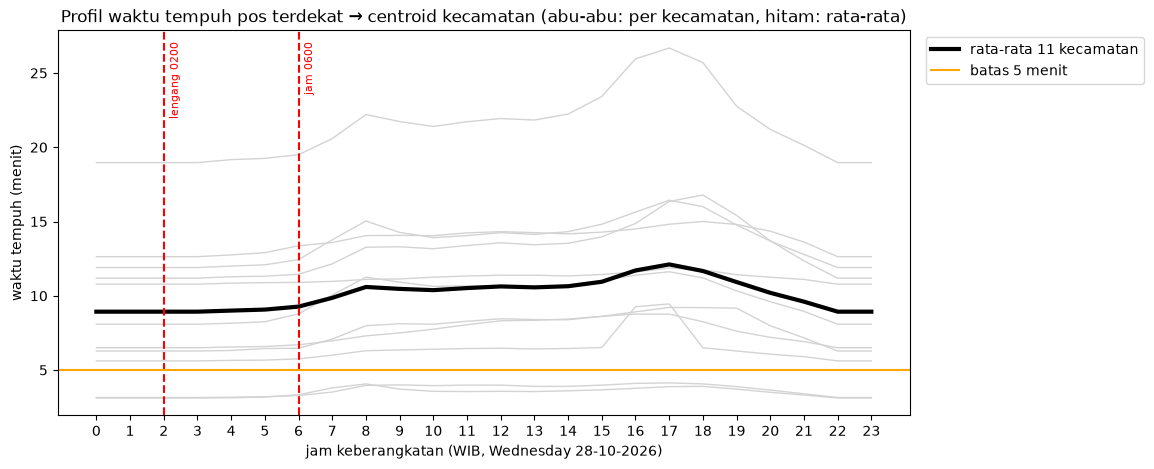

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Kecamatan,,,,,,,,,,,,,,,,,,,,,
Bulak,10.8,10.8,10.8,10.8,10.8,10.9,10.9,11.0,11.1,11.1,...,11.3,11.4,11.6,11.9,11.8,11.4,11.2,11.1,10.8,10.8
Genteng,6.5,6.5,6.5,6.5,6.6,6.6,6.7,7.0,7.3,7.5,...,8.4,8.6,8.8,8.8,8.2,7.6,7.2,6.9,6.5,6.5
Gubeng,3.2,3.2,3.2,3.2,3.2,3.2,3.3,3.5,4.0,4.0,...,3.9,4.0,4.1,4.1,4.1,3.9,3.6,3.4,3.2,3.2
Gunung Anyar,11.2,11.2,11.2,11.2,11.3,11.3,11.4,12.2,13.3,13.3,...,13.5,14.0,14.9,16.4,16.8,15.4,13.7,12.4,11.2,11.2
Kenjeran,12.6,12.6,12.6,12.6,12.8,12.9,13.4,13.6,14.0,14.1,...,14.2,14.3,14.5,14.8,15.0,14.8,14.4,13.6,12.6,12.6
Mulyorejo,11.9,11.9,11.9,11.9,12.0,12.1,12.4,13.8,15.0,14.3,...,14.3,14.8,15.6,16.4,16.0,14.8,13.7,12.8,11.9,11.9
Rungkut,19.0,19.0,19.0,19.0,19.2,19.2,19.5,20.6,22.2,21.7,...,22.2,23.4,26.0,26.7,25.7,22.8,21.2,20.1,19.0,19.0
Sukolilo,3.1,3.1,3.1,3.1,3.1,3.2,3.3,3.8,4.1,3.7,...,3.6,3.7,3.8,3.9,3.9,3.7,3.5,3.3,3.1,3.1
Tambaksari,6.3,6.3,6.3,6.3,6.3,6.4,6.5,7.1,8.0,8.1,...,8.4,8.6,8.9,9.2,9.2,9.2,8.0,7.2,6.3,6.3


In [13]:
# sampel: pos terdekat (garis lurus) ke centroid tiap kecamatan, 11 rute x 24 jam
terdekat_lurus = [pos_m.distance(c).idxmin() for c in kec_m.centroid]
profil = pd.DataFrame({jam: [rute(pos.geometry[i], t, jam)[0] for i, t in zip(terdekat_lurus, tujuan)] for jam in range(24)},
                      index=kec_m["Kecamatan"])
simpan_cache()

rata = profil.mean()
# 00.00-03.00 biasanya sama lengangnya; kalau seri pilih 02.00 sesuai laporan
JAM_LENGANG = min(range(6), key=lambda j: (round(rata[j], 1), abs(j - 2)))
JAM_PAGI = int(rata.loc[5:11].idxmax())
JAM_SORE = int(rata.loc[12:20].idxmax())
SKENARIO = {f"lengang_{JAM_LENGANG:02d}00": JAM_LENGANG,
            f"puncak_pagi_{JAM_PAGI:02d}00": JAM_PAGI,
            f"puncak_sore_{JAM_SORE:02d}00": JAM_SORE}
if JAM_SKENARIO is not None:   # diatur manual di cell konfigurasi: satu jam (6), daftar [2, 5, 17], atau {nama: jam}
    if isinstance(JAM_SKENARIO, dict):
        pilihan = list(JAM_SKENARIO.items())
    else:
        pilihan = [("jam", j) for j in ([JAM_SKENARIO] if isinstance(JAM_SKENARIO, int) else JAM_SKENARIO)]
        if len(pilihan) == 1:   # satu jam saja: pembandingnya jam lengang otomatis
            pilihan.insert(0, ("lengang", JAM_LENGANG))
    assert all(isinstance(j, int) and 0 <= j <= 23 for _, j in pilihan), "JAM_SKENARIO: jam harus bilangan bulat 0-23 (tulis 5, bukan 05)"
    SKENARIO = {f"{nama}_{jam:02d}00": jam for nama, jam in pilihan}
    assert len(set(SKENARIO.values())) >= 2, "JAM_SKENARIO: minimal 2 jam yang berbeda (satu jam dibandingkan dengan jam lengang otomatis, jadi jangan sama dengan jam lengang)"
print("Skenario terpilih:", SKENARIO)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(profil.columns, profil.T.values, color="lightgray", linewidth=1)   # tanpa label: tidak masuk legend
ax.plot(rata.index, rata.values, color="black", linewidth=3, label="rata-rata 11 kecamatan")
for nama, jam in SKENARIO.items():
    ax.axvline(jam, color="red", linestyle="--")
    ax.text(jam + 0.15, 0.97, nama.replace("_", " "), transform=ax.get_xaxis_transform(), rotation=90, va="top", fontsize=8, color="red")
ax.axhline(BATAS_TEMPUH_MENIT, color="orange", label=f"batas {BATAS_TEMPUH_MENIT} menit")
ax.set_xticks(range(24))
ax.set_xlabel(f"jam keberangkatan (WIB, {TANGGAL_SAMPEL:%A %d-%m-%Y})")
ax.set_ylabel("waktu tempuh (menit)")
ax.set_title("Profil waktu tempuh pos terdekat → centroid kecamatan (abu-abu: per kecamatan, hitam: rata-rata)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig(OUT / "profil_waktu_tempuh_24jam.png", dpi=200, bbox_inches="tight")
plt.show()
profil.round(1)

### 6.2 Waktu tempuh rute pos tercepat per kecamatan

In [14]:
rute_df = pd.DataFrame([{"skenario": nama, "pos": pn, "key": k, "menit": m, "km": km}
                        for nama, jam in SKENARIO.items()
                        for pn, pg in zip(pos["nama"], pos.geometry)
                        for k, t in zip(kec_m["key"], tujuan)
                        for m, km in [rute(pg, t, jam)]])
simpan_cache()

tempuh = kec_m[["key", "Kecamatan", "jumlah_kejadian", "status"]].copy()
for nama in SKENARIO:
    t = rute_df[rute_df["skenario"] == nama].reset_index(drop=True)
    terdekat = t.loc[t.groupby("key")["menit"].idxmin()].set_index("key")   # pos tercepat per kecamatan
    tempuh[f"menit_{nama}"] = tempuh["key"].map(terdekat["menit"]).round(1)
    tempuh[f"pos_{nama}"] = tempuh["key"].map(terdekat["pos"])
    tempuh[f"ok_{nama}"] = tempuh[f"menit_{nama}"] <= BATAS_TEMPUH_MENIT

lengang, *puncak = SKENARIO
tempuh["lolos_lengang_gagal_puncak"] = tempuh[f"ok_{lengang}"] & ~tempuh[[f"ok_{p}" for p in puncak]].all(axis=1)
ringkasan = tempuh.drop(columns="key").sort_values("jumlah_kejadian", ascending=False)
ringkasan.to_csv(OUT / "ringkasan_per_kecamatan.csv", index=False)
ringkasan

,Kecamatan,jumlah_kejadian,status,menit_lengang_0200,pos_lengang_0200,ok_lengang_0200,menit_jam_0600,pos_jam_0600,ok_jam_0600,lolos_lengang_gagal_puncak
7,Sukolilo,21,terjangkau,3.1,Pos Sukolilo (Keputih),True,3.3,Pos Sukolilo (Keputih),True,False
0,Bulak,19,terjangkau,10.8,Pos Bulak,False,10.9,Pos Bulak,False,False
3,Gunung Anyar,17,terjangkau sebagian,11.2,Pos Kali Rungkut,False,11.4,Pos Kali Rungkut,False,False
4,Kenjeran,16,terjangkau,11.9,UPTD II Tambak Rejo,False,12.7,UPTD II Tambak Rejo,False,False
2,Gubeng,15,terjangkau,3.2,Pos Menur,True,3.3,Pos Menur,True,False
8,Tambaksari,13,terjangkau,6.3,UPTD II Tambak Rejo,False,6.5,UPTD II Tambak Rejo,False,False
6,Rungkut,11,terjangkau sebagian,12.1,Pos Kali Rungkut,False,12.4,Pos Kali Rungkut,False,False
5,Mulyorejo,11,terjangkau sebagian,11.9,Pos Sukolilo (Keputih),False,12.4,Pos Sukolilo (Keputih),False,False
1,Genteng,10,terjangkau,6.5,Mako Pasar Turi,False,6.7,Mako Pasar Turi,False,False
10,Wonocolo,10,terjangkau,8.1,Rayon/UPTD III (SIER),False,8.8,Rayon/UPTD III (SIER),False,False


In [15]:
peta = kec_m.merge(tempuh.drop(columns=["Kecamatan", "jumlah_kejadian", "status"]), on="key")
vmax = peta[[f"menit_{s}" for s in SKENARIO]].max().max()
skala_menit = lambda: LinearColormap(["green", "yellow", "red"], vmin=0, vmax=vmax, caption="Waktu tempuh rute pos tercepat (menit)")
warna_menit = skala_menit()

for nama in SKENARIO:
    kolom, ok = f"menit_{nama}", f"ok_{nama}"
    m = peta_baru()
    folium.GeoJson(wgs(peta[["Kecamatan", "jumlah_kejadian", kolom, f"pos_{nama}", ok, "geometry"]]),
                   style_function=lambda f, k=kolom, o=ok: {"fillColor": warna_menit(f["properties"][k]), "fillOpacity": 0.6,
                                                            "color": "black" if f["properties"][o] else "red",   # garis merah tebal = lewat batas
                                                            "weight": 1 if f["properties"][o] else 3},
                   tooltip=folium.GeoJsonTooltip(fields=["Kecamatan", "jumlah_kejadian", kolom, f"pos_{nama}"],
                                                 aliases=["Kecamatan", f"Kejadian {TAHUN}", f"Menit ({label(nama)})", "Pos tercepat"])).add_to(m)
    tandai_pos(m)
    skala_menit().add_to(m)
    judul(m, f"Waktu tempuh {label(nama)} (garis merah: lebih dari {BATAS_TEMPUH_MENIT} menit)")
    display(simpan(m, f"peta_waktu_tempuh_{nama}"))

print("Kecamatan memenuhi batas saat lengang tapi tidak saat jam puncak:")
print(tempuh.loc[tempuh["lolos_lengang_gagal_puncak"], "Kecamatan"].tolist() or "-")

Peta tersimpan: output\peta_waktu_tempuh_lengang_0200.html


Peta tersimpan: output\peta_waktu_tempuh_jam_0600.html


Kecamatan memenuhi batas saat lengang tapi tidak saat jam puncak:
-


Peta rute (Folium): jalur jalan dari pos tercepat ke centroid tiap kecamatan, geometri dari respons TomTom yang sudah di-cache. Satu peta per skenario jam.

In [16]:
from shapely.geometry import LineString

def garis_rute(asal, tujuan, jam):
    r = tomtom("calculateRoute", f"{asal.y},{asal.x}:{tujuan.y},{tujuan.x}", routeType="fastest", departAt=berangkat(jam))["routes"][0]
    return LineString([(t["longitude"], t["latitude"]) for leg in r["legs"] for t in leg["points"]])

geom_pos = dict(zip(pos["nama"], pos.geometry))
geom_tujuan = dict(zip(kec_m["key"], tujuan))

for nama, jam in SKENARIO.items():
    m = peta_baru()
    folium.GeoJson(wgs(kec_m[["Kecamatan", "geometry"]]),
                   style_function=lambda f: {"fillColor": "#f5f5f5", "fillOpacity": 0.3, "color": "gray", "weight": 1},
                   tooltip=folium.GeoJsonTooltip(fields=["Kecamatan"], aliases=["Kecamatan"])).add_to(m)
    for k, p, kec_nama, menit in zip(tempuh["key"], tempuh[f"pos_{nama}"], tempuh["Kecamatan"], tempuh[f"menit_{nama}"]):
        garis = garis_rute(geom_pos[p], geom_tujuan[k], jam)
        folium.PolyLine([(y, x) for x, y in garis.coords], color=warna_menit(menit), weight=5, opacity=0.9,
                        tooltip=f"{p} → {kec_nama}: {menit} menit").add_to(m)
        folium.CircleMarker((geom_tujuan[k].y, geom_tujuan[k].x), radius=4, color="black", fill=True, fill_opacity=1,
                            tooltip=f"Centroid {kec_nama}").add_to(m)
    tandai_pos(m)
    skala_menit().add_to(m)
    judul(m, f"Rute pos tercepat → centroid kecamatan, {label(nama)}")
    display(simpan(m, f"peta_rute_{nama}"))
simpan_cache()

Peta tersimpan: output\peta_rute_lengang_0200.html


Peta tersimpan: output\peta_rute_jam_0600.html


## 7. Titik kejadian sebenarnya vs buffer *(di luar proposal, disetujui)*
Proposal menyebut "lokasi kejadian yang sebenarnya" sebagai pengembangan berikutnya. Bagian ini menguji berapa persen kejadian 2026 (titik koordinat SIJALINMAJA)
yang jatuh di dalam buffer pos (2,5 km pembantu, 3,5 km rayon). Kecamatan tiap titik ditentukan dari posisinya (point-in-polygon).

In [17]:
titik = gpd.GeoDataFrame(raw, geometry=gpd.points_from_xy(raw["lon"], raw["lat"]), crs="EPSG:4326").to_crs(CRS_UTM)   # raw dari bagian 1
n_awal = len(titik)
titik = gpd.sjoin(titik, kec_m[["key", "Kecamatan", "geometry"]], predicate="within").drop(columns="index_right")
beda = (titik["key"] != titik["nama_kecamatan"].map(kunci)).sum()
print(f"{len(titik)} dari {n_awal} titik {TAHUN} di dalam 11 kecamatan; {beda} titik tercatat di kecamatan tetangga (dekat batas)")

titik["dalam_buffer"] = titik.within(buffer_m.union_all())
persen = lambda s: round(s.mean() * 100, 1)
cakupan = titik.groupby("Kecamatan").agg(kejadian=("id", "size"), respon_median=("respon_time", "median"),
                                         persen_dalam_buffer=("dalam_buffer", persen))
cakupan.loc["TOTAL"] = [len(titik), titik["respon_time"].median(), persen(titik["dalam_buffer"])]
cakupan.to_csv(OUT / f"cakupan_titik_{TAHUN}.csv")
cakupan.sort_values("kejadian", ascending=False)

146 dari 147 titik 2026 di dalam 11 kecamatan; 2 titik tercatat di kecamatan tetangga (dekat batas)


,kejadian,respon_median,persen_dalam_buffer
Kecamatan,,,
TOTAL,146,5.0,80.1
Sukolilo,20,5.0,100.0
Bulak,19,5.0,84.2
Gunung Anyar,16,5.5,12.5
Kenjeran,16,5.5,81.2
Gubeng,14,4.5,100.0
Tambaksari,13,5.0,100.0
Mulyorejo,13,6.0,53.8
Rungkut,11,5.0,72.7


## 8. Peta gabungan interaktif (Folium)
Semua layer dalam satu peta; nyalakan/matikan lewat kontrol layer di kanan atas. Arahkan kursor ke kecamatan, rute, atau titik untuk detail.
Peta bagian 5 dan 6 juga memakai Folium (satu peta per skenario). Semuanya tersimpan sebagai HTML di `output/` dan bisa dibuka di browser tanpa Python.

In [18]:
m = peta_baru()

info = kec_m[["key", "geometry"]].merge(tempuh, on="key")
kolom = ["Kecamatan", "jumlah_kejadian", "status"] + [f"menit_{n}" for n in SKENARIO]
alias = ["Kecamatan", f"Kejadian {TAHUN}", "Status buffer"] + [f"Menit {label(n)}" for n in SKENARIO]
choro = folium.Choropleth(wgs(info[["key", "geometry"] + kolom]), data=info, columns=["key", "jumlah_kejadian"], key_on="feature.properties.key",
                          fill_color="YlOrRd", fill_opacity=0.45, line_opacity=0.8, legend_name=f"Jumlah kejadian kebakaran {TAHUN}",
                          name=f"Kejadian {TAHUN} per kecamatan").add_to(m)
choro.geojson.add_child(folium.GeoJsonTooltip(fields=kolom, aliases=alias))

folium.GeoJson(wgs(buffer_m[["nama", "radius_m", "geometry"]]), name="Buffer (garis lurus)",
               style_function=lambda f: {"color": "gray", "dashArray": "6,6", "weight": 1, "fill": False},
               tooltip=folium.GeoJsonTooltip(fields=["nama", "radius_m"], aliases=["Pos", "Radius (m)"])).add_to(m)

for i, (nama, jam) in enumerate(SKENARIO.items()):
    fg = folium.FeatureGroup(name=f"Rute pos tercepat — {label(nama)}", show=False)
    for k, p, kec_nama, menit in zip(tempuh["key"], tempuh[f"pos_{nama}"], tempuh["Kecamatan"], tempuh[f"menit_{nama}"]):
        garis = garis_rute(geom_pos[p], geom_tujuan[k], jam)
        folium.PolyLine([(y, x) for x, y in garis.coords], color=warna_menit(menit), weight=4, opacity=0.9,
                        tooltip=f"{p} → {kec_nama}: {menit} menit ({label(nama)})").add_to(fg)
    fg.add_to(m)
skala_menit().add_to(m)

fg = folium.FeatureGroup(name=f"Titik kejadian {TAHUN} (SIJALINMAJA)")
for _, r in wgs(titik).iterrows():
    # teks dari data luar di-escape sebelum masuk HTML popup
    teks = (f"<b>{escape(str(r['tanggal_kejadian']))} {escape(str(r['jam_kejadian']))}</b><br>{escape(str(r['lokasi_kejadian']))}<br>"
            f"{escape(str(r['objek']))}<br>Response time: {r['respon_time']} menit")
    folium.CircleMarker((r.geometry.y, r.geometry.x), radius=4, color="darkred", fill=True, fill_opacity=0.8, weight=1,
                        popup=folium.Popup(teks, max_width=250)).add_to(fg)
fg.add_to(m)

tandai_pos(m)
folium.LayerControl(collapsed=False).add_to(m)
simpan(m, "peta_interaktif")

Peta tersimpan: output\peta_interaktif.html


## 9. Self-check logika status jangkauan

In [19]:
from shapely.geometry import Point, box
_k = gpd.GeoDataFrame({"key": ["a", "b", "c"]}, geometry=[box(0, 0, 10, 10), box(20, 0, 30, 10), box(100, 0, 110, 10)], crs=CRS_UTM)
_b = gpd.GeoDataFrame({"nama": ["p1"]}, geometry=[Point(5, 5).buffer(3)], crs=CRS_UTM)
_b2 = gpd.GeoDataFrame({"nama": ["p1", "p2"]}, geometry=[Point(5, 5).buffer(3), Point(18, 5).buffer(4)], crs=CRS_UTM)
assert list(status_jangkauan(_k, _b)[0]) == ["terjangkau", "belum terjangkau", "belum terjangkau"]
assert list(status_jangkauan(_k, _b2)[0]) == ["terjangkau", "terjangkau sebagian", "belum terjangkau"]
print("OK")

OK
